# 🔬 Silica Gel Condition Dataset: Data Augmentation & Balancing Pipeline

This notebook implements an automated, domain-aware data augmentation pipeline to expand and balance the image samples for **Blue Silica Gel** and **Orange Silica Gel** across three distinct saturation states:
- **`initial`** (Fresh / Dry / Active)
- **`unsaturated`** (Partially saturated / Absorbing humidity)
- **`saturated`** (Fully exhausted / Moisture capacity reached)

---

### 🧪 Chemical & Domain Considerations
1. **Color Integrity is Critical**: 
   - **Blue Silica Gel** utilizes Cobalt Chloride indicator: changes from **Deep Blue** (initial) $\to$ **Purple/Mauve** (unsaturated) $\to$ **Pink/Light Rose** (saturated).
   - **Orange Silica Gel** utilizes organic/iron-based indicators: changes from **Vibrant Orange** (initial) $\to$ **Olive Green/Yellow-Green** (unsaturated) $\to$ **Dark Teal/Green/Blackish** (saturated).
   - ⚠️ **Key Rule**: We **strictly forbid aggressive Hue shifts or color inversion** because chromaticity is the ground-truth distinguishing feature.
2. **Geometric Invariance**:
   - Silica gel beads and petri dishes/vials are isotropic (rotationally invariant). Full $360^\circ$ rotations, horizontal/vertical flips, perspective shifts, and slight affine scales are physically authentic.
3. **Lighting & Sensor Robustness**:
   - Mild brightness ($\pm 12\%$), contrast ($\pm 12\%$), gentle Gaussian blur, and subtle camera sensor noise simulate diverse camera lenses and laboratory ambient lighting without corrupting color labels.


In [1]:
import os
import glob
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torchvision
import torchvision.transforms.v2 as T

# Seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Dataset configuration
BASE_DIR = os.getcwd()
GEL_FOLDERS = ['blue_silicagel', 'orange_silicagel']
CONDITIONS = ['initial', 'unsaturated', 'saturated']
TARGET_SAMPLES_PER_CONDITION = 50
VALID_EXTENSIONS = ('.jpeg', '.jpg', '.png', '.JPEG', '.JPG', '.PNG')
AUG_PREFIX = 'aug_'

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"Target samples per condition: {TARGET_SAMPLES_PER_CONDITION}")
print(f"Target total across all 6 categories: {TARGET_SAMPLES_PER_CONDITION * len(GEL_FOLDERS) * len(CONDITIONS)}")


PyTorch version: 2.6.0+cu124
Torchvision version: 0.21.0+cu124
Target samples per condition: 50
Target total across all 6 categories: 300


## 1. Baseline Dataset Inventory & Audit

Before generating any new images, let's scan each condition directory to assess the baseline distribution of original samples vs. existing augmented files.


In [2]:
def scan_dataset(base_dir, gel_folders, conditions, aug_prefix=AUG_PREFIX):
    inventory = {}
    for gel in gel_folders:
        inventory[gel] = {}
        for cond in conditions:
            folder_path = os.path.join(base_dir, gel, cond)
            if not os.path.isdir(folder_path):
                os.makedirs(folder_path, exist_ok=True)
            
            all_files = [f for f in os.listdir(folder_path) if f.lower().endswith(VALID_EXTENSIONS)]
            orig_files = [f for f in all_files if not f.startswith(aug_prefix)]
            aug_files = [f for f in all_files if f.startswith(aug_prefix)]
            
            inventory[gel][cond] = {
                'path': folder_path,
                'orig': orig_files,
                'aug': aug_files,
                'total': len(all_files)
            }
    return inventory

inventory = scan_dataset(BASE_DIR, GEL_FOLDERS, CONDITIONS)

print("=" * 70)
print(f"{'Gel Type':<18} | {'Condition':<14} | {'Originals':<10} | {'Augmented':<10} | {'Total':<6}")
print("=" * 70)
for gel in GEL_FOLDERS:
    for cond in CONDITIONS:
        data = inventory[gel][cond]
        print(f"{gel:<18} | {cond:<14} | {len(data['orig']):<10} | {len(data['aug']):<10} | {data['total']:<6}")
print("=" * 70)


Gel Type           | Condition      | Originals  | Augmented  | Total 
blue_silicagel     | initial        | 5          | 0          | 5     
blue_silicagel     | unsaturated    | 6          | 0          | 6     
blue_silicagel     | saturated      | 6          | 0          | 6     
orange_silicagel   | initial        | 5          | 0          | 5     
orange_silicagel   | unsaturated    | 5          | 0          | 5     
orange_silicagel   | saturated      | 10         | 0          | 10    


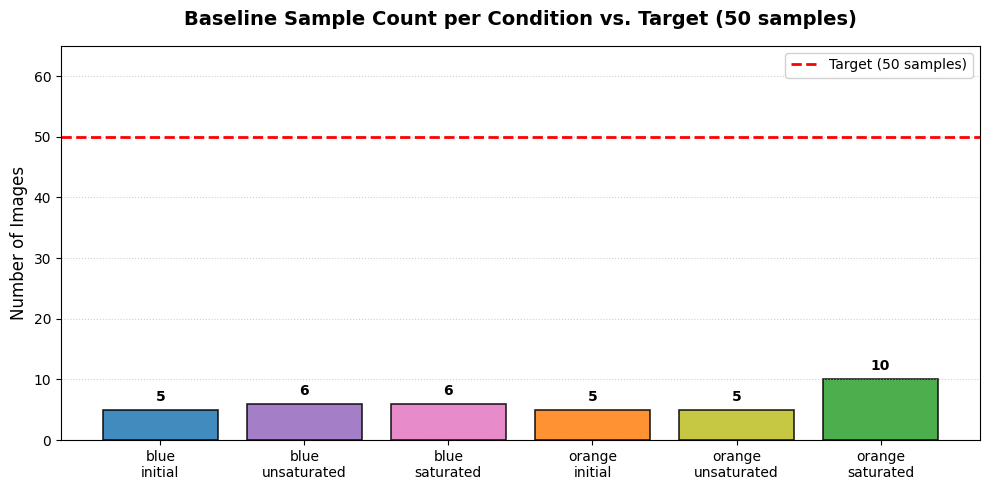

In [3]:
# Visualize baseline class distribution vs Target
categories = []
orig_counts = []
colors = []

color_map = {
    ('blue_silicagel', 'initial'): '#1f77b4',
    ('blue_silicagel', 'unsaturated'): '#9467bd',
    ('blue_silicagel', 'saturated'): '#e377c2',
    ('orange_silicagel', 'initial'): '#ff7f0e',
    ('orange_silicagel', 'unsaturated'): '#bcbd22',
    ('orange_silicagel', 'saturated'): '#2ca02c',
}

for gel in GEL_FOLDERS:
    for cond in CONDITIONS:
        categories.append(f"{gel.split('_')[0]}\n{cond}")
        orig_counts.append(len(inventory[gel][cond]['orig']))
        colors.append(color_map.get((gel, cond), '#7f7f7f'))

plt.figure(figsize=(10, 5))
bars = plt.bar(categories, orig_counts, color=colors, edgecolor='black', linewidth=1.2, alpha=0.85)
plt.axhline(TARGET_SAMPLES_PER_CONDITION, color='red', linestyle='--', linewidth=2, label=f'Target ({TARGET_SAMPLES_PER_CONDITION} samples)')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')

plt.title('Baseline Sample Count per Condition vs. Target (50 samples)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Number of Images', fontsize=12)
plt.ylim(0, max(orig_counts + [TARGET_SAMPLES_PER_CONDITION]) + 15)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


## 2. Domain-Aware Augmentation Pipeline

We construct an augmentation pipeline designed specifically for chemical indicator granules:
- **`RandomHorizontalFlip` (p=0.5)** & **`RandomVerticalFlip` (p=0.5)**
- **`RandomRotation` (0° to 360°)**: Complete rotational invariance.
- **`RandomAffine`**: Mild translations ($\pm 6\%$), scale changes ($0.92$ to $1.08$), and shear ($\pm 6^\circ$).
- **`RandomPerspective` (p=0.4)**: Simulates oblique viewing angles when photographed.
- **`ColorJitter`**: Mild brightness ($\pm 12\%$), contrast ($\pm 12\%$), saturation ($\pm 8\%$), with **`hue=0.0`** strictly locked to maintain the chemical indicator's color state.
- **`GaussianBlur` (p=0.35)**: Simulates camera autofocus softness.
- **`Sensor Noise`**: Subtle zero-mean Gaussian noise ($\sigma=0.015$) to prevent over-reliance on smooth background pixels.


In [4]:
# Core Torchvision transforms pipeline
torchvision_aug = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=(0, 360), interpolation=T.InterpolationMode.BILINEAR),
    T.RandomAffine(
        degrees=0,
        translate=(0.06, 0.06),
        scale=(0.92, 1.08),
        shear=(-6, 6, -6, 6),
        interpolation=T.InterpolationMode.BILINEAR
    ),
    T.RandomPerspective(distortion_scale=0.15, p=0.4),
    T.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08, hue=0.0),
    T.RandomApply([T.GaussianBlur(kernel_size=(3, 5), sigma=(0.1, 1.2))], p=0.35)
])

def apply_sensor_noise(image_pil, p=0.35, sigma=0.015):
    """Applies subtle zero-mean Gaussian sensor noise without altering overall tint."""
    if random.random() < p:
        arr = np.array(image_pil, dtype=np.float32) / 255.0
        noise = np.random.normal(0.0, sigma, arr.shape)
        noisy = np.clip(arr + noise, 0.0, 1.0)
        return Image.fromarray((noisy * 255).astype(np.uint8))
    return image_pil

def augment_image(image_pil):
    """Complete augmentation pipeline for a single PIL image."""
    # Ensure RGB
    img_rgb = image_pil.convert('RGB')
    # Geometric & safe color adjustments
    transformed = torchvision_aug(img_rgb)
    # Sensor noise
    final_img = apply_sensor_noise(transformed, p=0.35, sigma=0.015)
    return final_img


## 3. Augmentation Visual Quality & Color Sanity Check

Let's preview an original image alongside 4 augmented variations for each condition to visually confirm that:
1. The indicator color classification (Blue vs. Purple vs. Pink; Orange vs. Olive vs. Dark Green) remains 100% unambiguous.
2. Geometric transformations introduce realistic diversity in bead arrangements, perspectives, and scales.


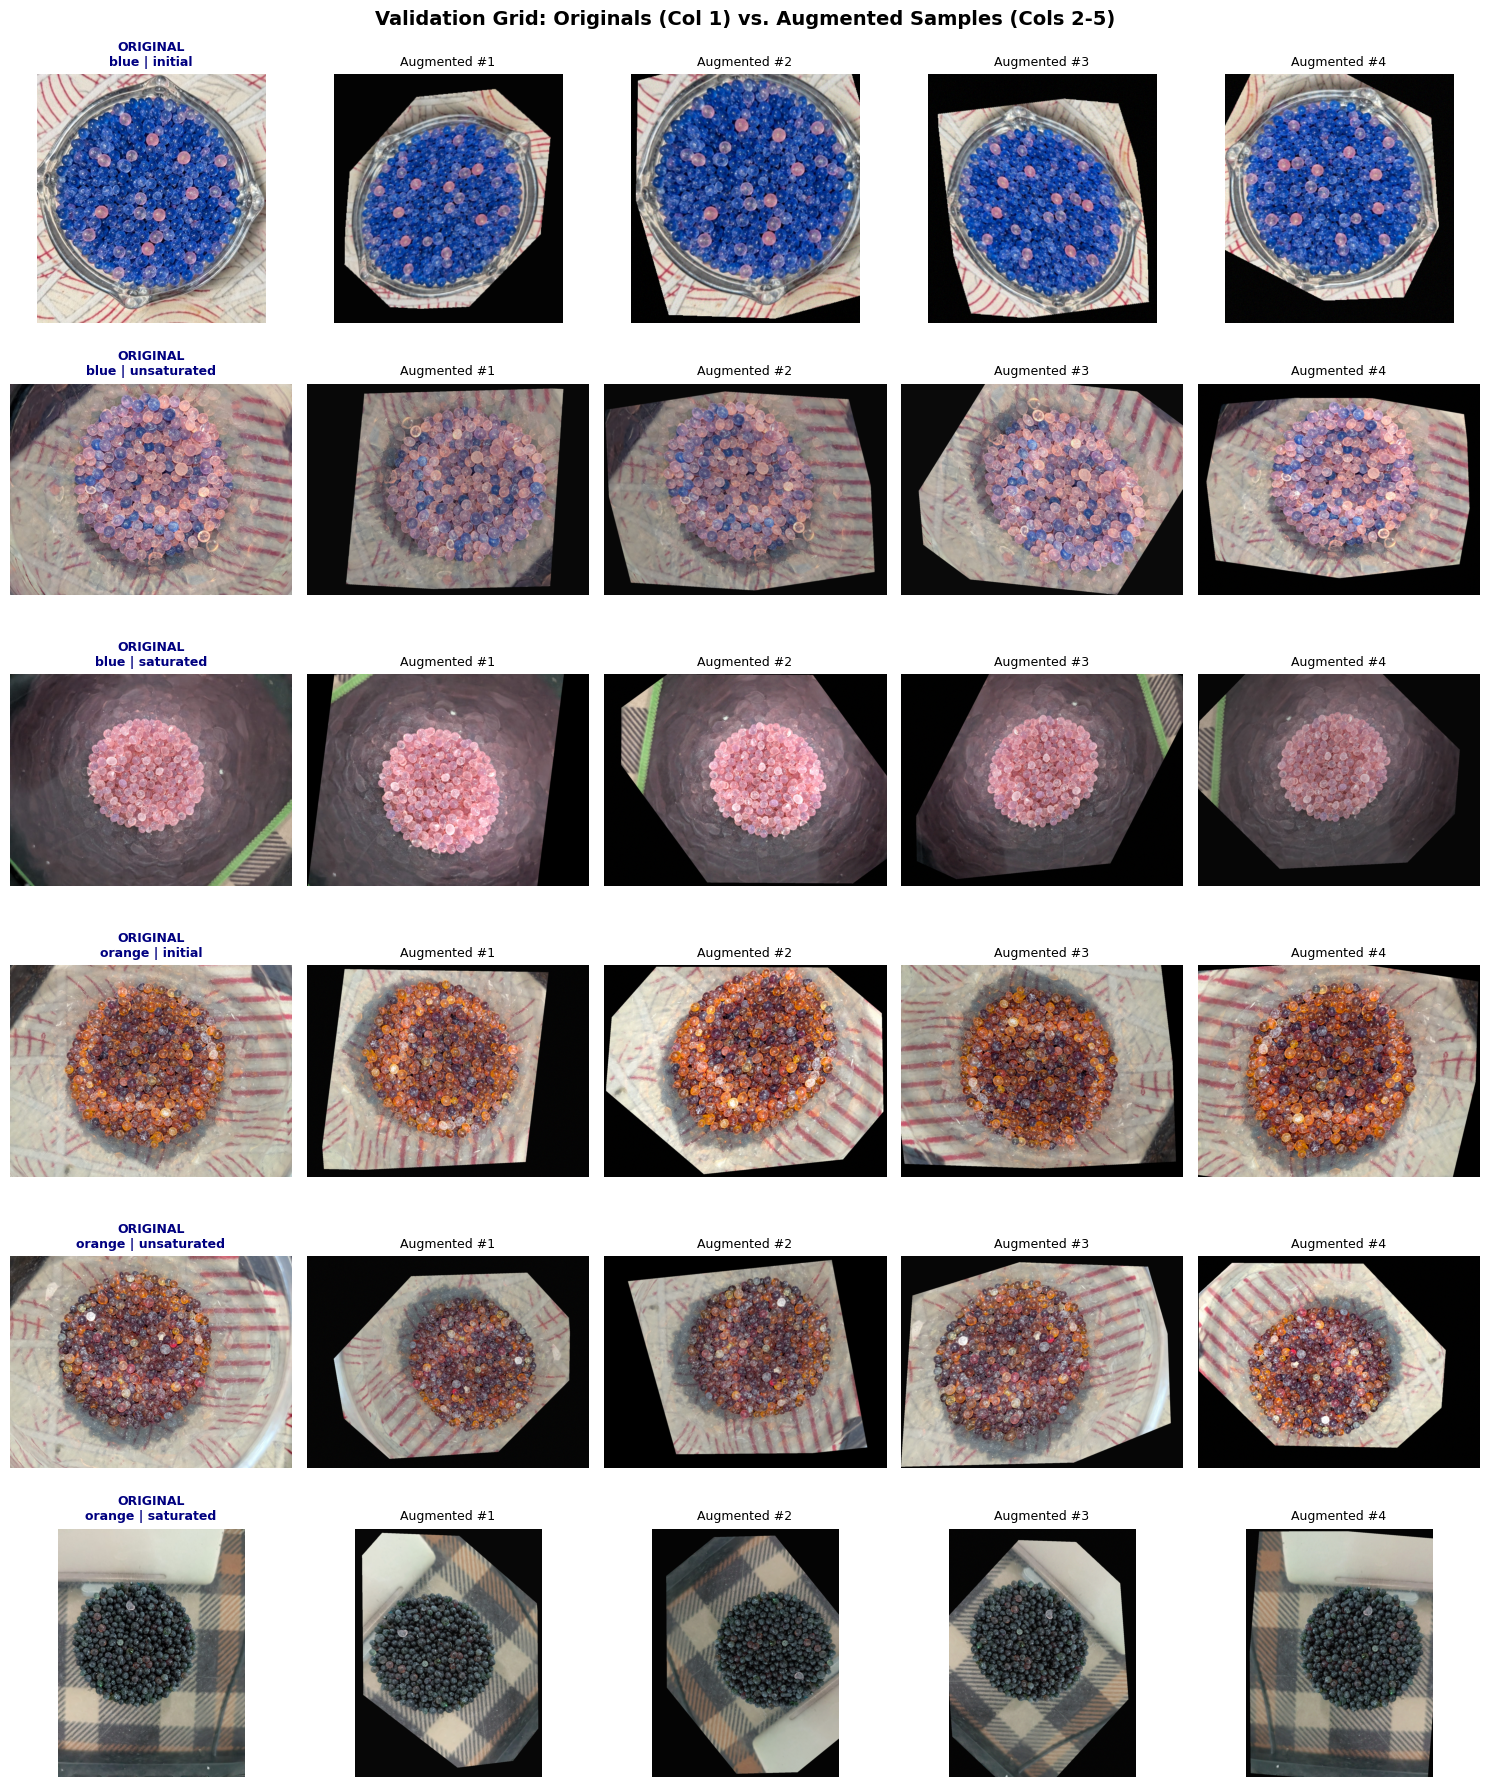

In [5]:
# Display sample original vs 4 augmented variants across all 6 conditions
fig, axes = plt.subplots(6, 5, figsize=(15, 18))
plt.subplots_adjust(hspace=0.4, wspace=0.1)

row = 0
for gel in GEL_FOLDERS:
    for cond in CONDITIONS:
        orig_files = inventory[gel][cond]['orig']
        if not orig_files:
            continue
        
        sample_path = os.path.join(inventory[gel][cond]['path'], orig_files[0])
        orig_img = Image.open(sample_path).convert('RGB')
        
        # Original in column 0
        axes[row, 0].imshow(orig_img)
        axes[row, 0].set_title(f"ORIGINAL\n{gel.split('_')[0]} | {cond}", fontsize=9, fontweight='bold', color='navy')
        axes[row, 0].axis('off')
        
        # 4 Augmented variations in columns 1..4
        for col in range(1, 5):
            aug_sample = augment_image(orig_img)
            axes[row, col].imshow(aug_sample)
            axes[row, col].set_title(f"Augmented #{col}", fontsize=9)
            axes[row, col].axis('off')
        
        row += 1

plt.suptitle("Validation Grid: Originals (Col 1) vs. Augmented Samples (Cols 2-5)", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


## 4. In-Place Dataset Augmentation Engine

We now expand each condition folder directly in-place:
- Only genuine original images are used as source seeds.
- Augmented files are saved directly in `initial`, `unsaturated`, and `saturated` folders with an `aug_` prefix.
- Every condition folder is brought to **exactly 50 samples**.
- High quality JPEG compression (`quality=95`) ensures no loss of bead detail.


In [6]:
def balance_and_augment_dataset(inventory, target_count=TARGET_SAMPLES_PER_CONDITION, aug_prefix=AUG_PREFIX):
    total_generated = 0
    generation_log = []
    
    for gel in GEL_FOLDERS:
        for cond in CONDITIONS:
            info = inventory[gel][cond]
            folder_path = info['path']
            orig_files = info['orig']
            aug_files = info['aug']
            
            current_total = len(orig_files) + len(aug_files)
            needed = target_count - current_total
            
            print(f"\nProcessing [{gel} / {cond}]:")
            print(f"   Originals: {len(orig_files)} | Existing Aug: {len(aug_files)} | Current: {current_total} | Target: {target_count}")
            
            if needed <= 0:
                print(f"   ✓ Already at or above target ({current_total}/{target_count}). No new augmentations needed.")
                generation_log.append((gel, cond, len(orig_files), len(aug_files), current_total))
                continue
            
            if len(orig_files) == 0:
                print(f"   ⚠️ WARNING: No original images found in {folder_path} to augment from!")
                continue
            
            print(f"   ⚡ Generating {needed} new augmented samples...")
            # Load all original images into memory to speed up augmentation
            loaded_origs = []
            for fname in orig_files:
                fpath = os.path.join(folder_path, fname)
                loaded_origs.append((fname, Image.open(fpath).convert('RGB')))
            
            # Start index after existing augmented files
            start_idx = len(aug_files) + 1
            
            for i in range(needed):
                idx = start_idx + i
                # Select source original cyclically
                orig_fname, orig_pil = loaded_origs[i % len(loaded_origs)]
                
                # Apply augmentation
                aug_pil = augment_image(orig_pil)
                
                # Clean filename stem
                orig_stem = os.path.splitext(orig_fname)[0]
                clean_stem = "".join(c if c.isalnum() else "_" for c in orig_stem)[:30]
                save_filename = f"{aug_prefix}{idx:03d}_{clean_stem}.jpeg"
                save_path = os.path.join(folder_path, save_filename)
                
                # Save high quality JPEG
                aug_pil.save(save_path, format="JPEG", quality=95)
                total_generated += 1
            
            final_count = len(orig_files) + len(aug_files) + needed
            print(f"   ✓ Successfully added {needed} samples. Total now = {final_count}")
            generation_log.append((gel, cond, len(orig_files), len(aug_files) + needed, final_count))
            
    return total_generated, generation_log

total_new, log = balance_and_augment_dataset(inventory, target_count=TARGET_SAMPLES_PER_CONDITION)
print(f"\n{'='*70}")
print(f"🎉 Augmentation complete! Total new augmented images generated: {total_new}")
print(f"{'='*70}")



Processing [blue_silicagel / initial]:
   Originals: 5 | Existing Aug: 0 | Current: 5 | Target: 50
   ⚡ Generating 45 new augmented samples...


   ✓ Successfully added 45 samples. Total now = 50

Processing [blue_silicagel / unsaturated]:
   Originals: 6 | Existing Aug: 0 | Current: 6 | Target: 50
   ⚡ Generating 44 new augmented samples...


   ✓ Successfully added 44 samples. Total now = 50

Processing [blue_silicagel / saturated]:
   Originals: 6 | Existing Aug: 0 | Current: 6 | Target: 50
   ⚡ Generating 44 new augmented samples...


   ✓ Successfully added 44 samples. Total now = 50

Processing [orange_silicagel / initial]:
   Originals: 5 | Existing Aug: 0 | Current: 5 | Target: 50
   ⚡ Generating 45 new augmented samples...


   ✓ Successfully added 45 samples. Total now = 50

Processing [orange_silicagel / unsaturated]:
   Originals: 5 | Existing Aug: 0 | Current: 5 | Target: 50
   ⚡ Generating 45 new augmented samples...


   ✓ Successfully added 45 samples. Total now = 50

Processing [orange_silicagel / saturated]:
   Originals: 10 | Existing Aug: 0 | Current: 10 | Target: 50
   ⚡ Generating 40 new augmented samples...


   ✓ Successfully added 40 samples. Total now = 50

🎉 Augmentation complete! Total new augmented images generated: 263


## 5. Post-Augmentation Verification & Summary

Let's re-scan all directories on disk to verify the exact counts and plot the balanced dataset.


In [7]:
# Re-scan disk to verify actual files
updated_inventory = scan_dataset(BASE_DIR, GEL_FOLDERS, CONDITIONS)

print("=" * 70)
print(f"{'Gel Type':<18} | {'Condition':<14} | {'Originals':<10} | {'Augmented':<10} | {'Final Total':<11}")
print("=" * 70)
grand_total = 0
for gel in GEL_FOLDERS:
    for cond in CONDITIONS:
        data = updated_inventory[gel][cond]
        grand_total += data['total']
        print(f"{gel:<18} | {cond:<14} | {len(data['orig']):<10} | {len(data['aug']):<10} | {data['total']:<11}")
print("=" * 70)
print(f"Grand Total Dataset Size: {grand_total} images (Target: {TARGET_SAMPLES_PER_CONDITION * 6})")
print("=" * 70)


Gel Type           | Condition      | Originals  | Augmented  | Final Total
blue_silicagel     | initial        | 5          | 45         | 50         
blue_silicagel     | unsaturated    | 6          | 44         | 50         
blue_silicagel     | saturated      | 6          | 44         | 50         
orange_silicagel   | initial        | 5          | 45         | 50         
orange_silicagel   | unsaturated    | 5          | 45         | 50         
orange_silicagel   | saturated      | 10         | 40         | 50         
Grand Total Dataset Size: 300 images (Target: 300)


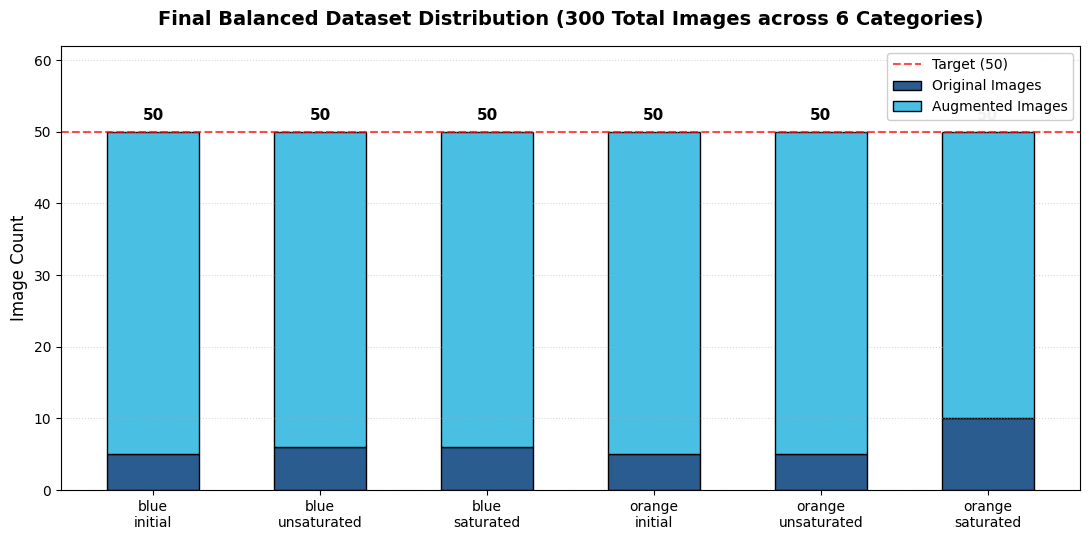

In [8]:
# Final balanced distribution chart
final_categories = []
final_orig = []
final_aug = []

for gel in GEL_FOLDERS:
    for cond in CONDITIONS:
        final_categories.append(f"{gel.split('_')[0]}\n{cond}")
        final_orig.append(len(updated_inventory[gel][cond]['orig']))
        final_aug.append(len(updated_inventory[gel][cond]['aug']))

x = np.arange(len(final_categories))
width = 0.55

plt.figure(figsize=(11, 5.5))
p1 = plt.bar(x, final_orig, width, label='Original Images', color='#2b5c8f', edgecolor='black', linewidth=1)
p2 = plt.bar(x, final_aug, width, bottom=final_orig, label='Augmented Images', color='#48bfe3', edgecolor='black', linewidth=1)

for i in range(len(final_categories)):
    tot = final_orig[i] + final_aug[i]
    plt.text(i, tot + 1.2, f"{tot}", ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.axhline(TARGET_SAMPLES_PER_CONDITION, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label=f'Target ({TARGET_SAMPLES_PER_CONDITION})')
plt.title(f'Final Balanced Dataset Distribution ({grand_total} Total Images across 6 Categories)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(x, final_categories, fontsize=10)
plt.ylabel('Image Count', fontsize=12)
plt.ylim(0, max(final_orig[i] + final_aug[i] for i in range(len(final_categories))) + 12)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.legend(frameon=True, facecolor='white', framealpha=0.95, loc='upper right')
plt.tight_layout()
plt.show()


## 6. Downstream Integration: PyTorch Dataset & DataLoader

Now that each condition folder is balanced, you can directly load either gel dataset using `torchvision.datasets.ImageFolder` or combine both into a hierarchical / multi-class classification setup for training Vision Transformers (ViT, Swin) or CNNs (ResNet, EfficientNet).


In [9]:
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

# Preprocessing transforms for Vision Transformer (e.g., ViT-B/16: 224x224)
import torchvision.transforms as standard_T

vit_transforms = standard_T.Compose([
    standard_T.Resize((224, 224)),
    standard_T.ToTensor(),
    standard_T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Example: Blue Silica Gel dataset loader
blue_dataset = ImageFolder(root=os.path.join(BASE_DIR, 'blue_silicagel'), transform=vit_transforms)
print(f"Blue Silica Gel Classes: {blue_dataset.classes}")
print(f"Blue Silica Gel Total Images: {len(blue_dataset)}")

# Example: Orange Silica Gel dataset loader
orange_dataset = ImageFolder(root=os.path.join(BASE_DIR, 'orange_silicagel'), transform=vit_transforms)
print(f"Orange Silica Gel Classes: {orange_dataset.classes}")
print(f"Orange Silica Gel Total Images: {len(orange_dataset)}")

# Example DataLoader
sample_loader = DataLoader(blue_dataset, batch_size=8, shuffle=True)
images_batch, labels_batch = next(iter(sample_loader))
print(f"\nSample batch loaded successfully: shape = {images_batch.shape}, labels = {labels_batch.tolist()}")


Blue Silica Gel Classes: ['initial', 'saturated', 'unsaturated']
Blue Silica Gel Total Images: 150
Orange Silica Gel Classes: ['initial', 'saturated', 'unsaturated']
Orange Silica Gel Total Images: 150



Sample batch loaded successfully: shape = torch.Size([8, 3, 224, 224]), labels = [2, 1, 0, 0, 0, 1, 2, 0]
